## Celda 1 - Lectura unificada

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

CARPETA = Path("datos")
SALIDA = Path("procesado")
SALIDA.mkdir(exist_ok=True)

COLUMNAS = ["Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"]

def convertir_fecha(serie):
    """Intenta el formato con segundos; si falla, usa dd/mm/aaaa hh:mm."""
    fecha = pd.to_datetime(serie, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    formato_corto = fecha.isna()
    fecha.loc[formato_corto] = pd.to_datetime(
        serie[formato_corto], format="%d/%m/%Y %H:%M", errors="coerce")
    return fecha, formato_corto

partes = []
for ruta in sorted(CARPETA.glob("20*/datos_abiertos_*.csv")):
    df = pd.read_csv(ruta, encoding="latin-1", usecols=[4, 5, 6, 7], dtype=str)
    df.columns = COLUMNAS
    inicio, corto = convertir_fecha(df["Inicio_del_viaje"])
    fin, _ = convertir_fecha(df["Fin_del_viaje"])
    anio, mes = map(int, ruta.stem.split("_")[-2:])

    partes.append(pd.DataFrame({
        "inicio": inicio,
        "fin": fin,
        "origen": pd.to_numeric(df["Origen_Id"], errors="coerce"),
        "destino": pd.to_numeric(df["Destino_Id"], errors="coerce"),
        "resolucion_minutos": corto,
        "archivo": f"{anio}-{mes:02d}",
    }))

    fuera_de_mes = ((inicio.dt.year != anio) | (inicio.dt.month != mes)).sum()
    print(f"{ruta.name}: {len(df):>8,} filas | formato corto: {corto.sum():>8,} "
          f"| fechas no convertidas: {inicio.isna().sum()} | fuera del mes: {fuera_de_mes}")

viajes = pd.concat(partes, ignore_index=True)
del partes
print(f"\nTotal: {len(viajes):,} viajes")
print(viajes.dtypes)

datos_abiertos_2024_01.csv:  391,591 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_02.csv:  383,732 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_03.csv:  390,513 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_04.csv:  405,308 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_05.csv:  410,806 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_06.csv:  365,000 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_07.csv:  364,177 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_08.csv:  394,894 filas | formato corto:        0 | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2024_09.csv:  390,072 filas | formato corto:  390,072 | fechas no

## Celda 2 - Analisis de duraciones

In [2]:
viajes["duracion_min"] = (viajes["fin"] - viajes["inicio"]).dt.total_seconds() / 60
d = viajes["duracion_min"]
misma = viajes["origen"] == viajes["destino"]

print(d.describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]).round(2))

resumen = {
    "Fechas faltantes": viajes[["inicio", "fin"]].isna().any(axis=1).sum(),
    "Estación faltante": viajes[["origen", "destino"]].isna().any(axis=1).sum(),
    "Duración negativa": (d < 0).sum(),
    "Duración < 1 min": (d < 1).sum(),
    "  ...misma estación": ((d < 1) & misma).sum(),
    "  ...distinta estación": ((d < 1) & ~misma).sum(),
    "Misma estación (total)": misma.sum(),
    "Misma estación y >= 1 min": (misma & (d >= 1)).sum(),
    "Duración > 30 min": (d > 30).sum(),
    "Duración > 60 min": (d > 60).sum(),
    "Duración > 3 h": (d > 180).sum(),
    "Duración > 24 h": (d > 1440).sum(),
}
print()
for nombre, valor in resumen.items():
    print(f"{nombre:<28}{valor:>12,}  ({valor / len(viajes):.3%})")

count    9177953.00
mean          11.10
std           10.03
min            0.00
0.1%           0.00
1%             0.22
5%             2.32
25%            5.85
50%            9.57
75%           14.93
95%           24.22
99%           32.83
99.9%         57.05
max        11500.77
Name: duracion_min, dtype: float64

Fechas faltantes                       0  (0.000%)
Estación faltante                      0  (0.000%)
Duración negativa                      0  (0.000%)
Duración < 1 min                 261,105  (2.845%)
  ...misma estación              242,946  (2.647%)
  ...distinta estación            18,159  (0.198%)
Misma estación (total)           555,621  (6.054%)
Misma estación y >= 1 min        312,675  (3.407%)
Duración > 30 min                140,216  (1.528%)
Duración > 60 min                  8,041  (0.088%)
Duración > 3 h                       991  (0.011%)
Duración > 24 h                       19  (0.000%)


## Celda 3 - Revisión de estaciones

In [3]:
nom = pd.read_csv(next(CARPETA.glob("nomenclatura*.csv")))

for anio in (2024, 2025):
    n = viajes.loc[viajes["inicio"].dt.year == anio, "origen"].nunique()
    print(f"{anio}: {n} estaciones de origen distintas")

sin_nom = sorted(set(viajes["origen"].dropna().astype(int)) - set(nom["id"]))
print("Estaciones en viajes que no están en la nomenclatura:", sin_nom)

meses_activos = viajes.groupby("origen")["archivo"].nunique()
print(f"Estaciones con viajes en los 24 meses: {(meses_activos == 24).sum()} de {len(meses_activos)}")

print("\nCapacidad de anclajes (dpcapacity):")
print(nom["dpcapacity"].describe().round(1))

2024: 370 estaciones de origen distintas
2025: 371 estaciones de origen distintas
Estaciones en viajes que no están en la nomenclatura: []
Estaciones con viajes en los 24 meses: 355 de 373

Capacidad de anclajes (dpcapacity):
count    484.0
mean      16.9
std        4.1
min        0.0
25%       15.0
50%       15.0
75%       19.0
max       39.0
Name: dpcapacity, dtype: float64


## Celda 4 - RGuardar lo cargado

In [4]:
viajes.to_parquet(SALIDA / "viajes_2024_2025.parquet", index=False)
print("Guardado:", SALIDA / "viajes_2024_2025.parquet")

Guardado: procesado/viajes_2024_2025.parquet


## Celda 5 - Grafica de duraciones cortas

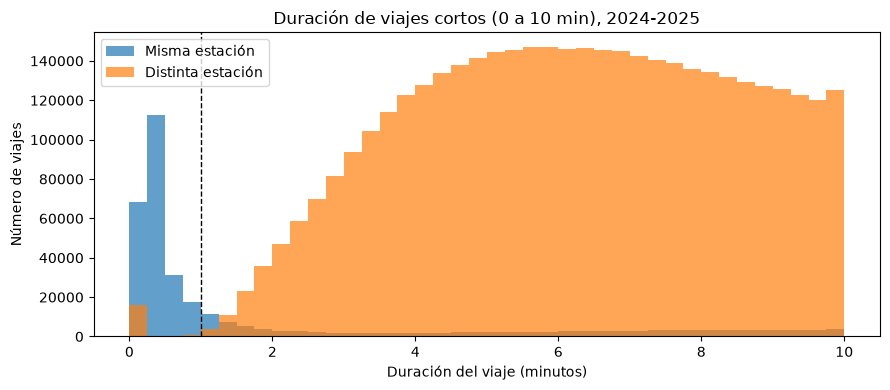

In [5]:
import matplotlib.pyplot as plt

FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

seg = viajes.loc[~viajes["resolucion_minutos"]]
bins = np.arange(0, 10.25, 0.25)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(seg.loc[seg["origen"] == seg["destino"], "duracion_min"], bins=bins, alpha=.7, label="Misma estación")
ax.hist(seg.loc[seg["origen"] != seg["destino"], "duracion_min"], bins=bins, alpha=.7, label="Distinta estación")
ax.axvline(1, color="black", ls="--", lw=1)
ax.set(xlabel="Duración del viaje (minutos)", ylabel="Número de viajes",
       title="Duración de viajes cortos (0 a 10 min), 2024-2025")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / "duracion_viajes_cortos.png", dpi=150)
plt.show()

## Celda 6 - Aplicar las reglas de limpieza

In [9]:
misma = viajes["origen"] == viajes["destino"]
regla1 = viajes["duracion_min"] < 1
regla2 = viajes["duracion_min"] > 1440

n0 = len(viajes)
print(f"Registros originales:                          {n0:>10,}")
print(f"Regla 1 (duración < 1 min):                    {regla1.sum():>10,}")
print(f"Regla 2 (duración > 24 h):                     {regla2.sum():>10,}")

limpios = viajes.loc[~(regla1 | regla2)].copy()
print(f"Registros después de la limpieza:              {len(limpios):>10,}  "
      f"({1 - len(limpios) / n0:.2%} eliminados)")

Registros originales:                           9,177,953
Regla 1 (duración < 1 min):                       261,105
Regla 2 (duración > 24 h):                             19
Registros después de la limpieza:               8,916,829  (2.85% eliminados)


## Celda 7 - Viajes por hora de inicio

In [10]:
por_hora = limpios["inicio"].dt.hour.value_counts().sort_index()
print(por_hora.to_string())

inicio
0      56160
1         22
5      69345
6     245345
7     492579
8     702877
9     499816
10    430494
11    432984
12    456332
13    522884
14    584321
15    590226
16    552717
17    670894
18    839026
19    633635
20    467677
21    357016
22    204411
23    108068


## Celda 8 - Selección de estaciones

In [11]:
activas = meses_activos[meses_activos == 24].index
es_2024 = limpios["inicio"].dt.year == 2024

salidas_2024 = (limpios.loc[es_2024 & limpios["origen"].isin(activas)]
                .groupby("origen").size().sort_values(ascending=False))
total_2024 = es_2024.sum()

for n in (10, 20, 30, 50, 100):
    print(f"Top {n:>3}: {salidas_2024.head(n).sum() / total_2024:.1%} de las salidas de 2024")

N = 30
seleccion = (salidas_2024.head(N).rename("salidas_2024").reset_index()
             .merge(nom, left_on="origen", right_on="id", how="left"))
print()
print(seleccion[["origen", "name", "dpcapacity", "salidas_2024"]].to_string(index=False))

Top  10: 12.8% de las salidas de 2024
Top  20: 20.1% de las salidas de 2024
Top  30: 26.5% de las salidas de 2024
Top  50: 37.3% de las salidas de 2024
Top 100: 58.2% de las salidas de 2024

 origen                                          name  dpcapacity  salidas_2024
     51       (GDL-049) Lopez Cotilla / Penitenciaría          39         93294
    271           (GDL-198) Av. Alcalde / C. Hospital          31         69017
     35         (GDL-033) Av. Hidalgo / C. Pedro Loza          15         67090
     11     (GDL-009) Calz. Federalismo/ C. J. Angulo          23         65406
     52         (GDL-050) C.Pedro Moreno /Federalismo          23         60892
     50 (GDL-048) C. Constancio Hernández/ Av. Juaréz          23         56290
     54        (GDL-052) Av. Juarez /16 de Septiembre          23         51912
     38   (GDL-036) C. Marcos Castellanos/ C. Morelos          23         38480
    260 (GDL-187) Av. 16 de Septiembre / C. Priscilia          15         36288
     34  

## Celda 9 - Guardar

In [12]:
limpios.to_parquet(SALIDA / "viajes_limpios.parquet", index=False)
seleccion.to_csv(SALIDA / "estaciones_seleccionadas.csv", index=False)
print("Guardado.")

Guardado.
